# Evaluation on Pascal VOC 2012

Runs the pipeline with several saliency methods (GradCAM and LRP variants) on Pascal VOC images
that contain a single object class, and compares the selected segmentation with the ground truth.

Needs Pascal VOC 2012 in `datasets/VOCSegmentation` (set `DOWNLOAD = True` once, about 2 GB).

In [1]:
import random

import numpy as np
import pandas as pd
import torch
from zennit.canonizers import SequentialMergeBatchNorm
from zennit.composites import EpsilonGammaBox, EpsilonPlus

from saliency_sam import load_resnet, load_sam, plotting
from saliency_sam.evaluation import Evaluator, label_table, load_pascal_voc, save_results, single_class_images
from saliency_sam.metrics import (AverageSurfaceDistance, AverageSymmetricSurfaceDistance, BoundaryIoU,
                                  DiceCoefficient, F1Score, HausdorffDistance, IoU, NormalizedSurfaceDistance,
                                  Precision, Recall)
from saliency_sam.xai import LRP, GradCAM

DOWNLOAD = False
N_SAMPLES = 5
SEED = 123

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

sam = load_sam("vit_b")  # the original evaluation used vit_h (scripts/download_checkpoints.sh --vit-h)
resnet = load_resnet()

## Dataset

Train and val sets, center-cropped to squares. Only images with exactly one class, without classes that ImageNet has no counterpart for.

reading masks:   0%|          | 0/2913 [00:00<?, ?it/s]

1509 of 2913 images


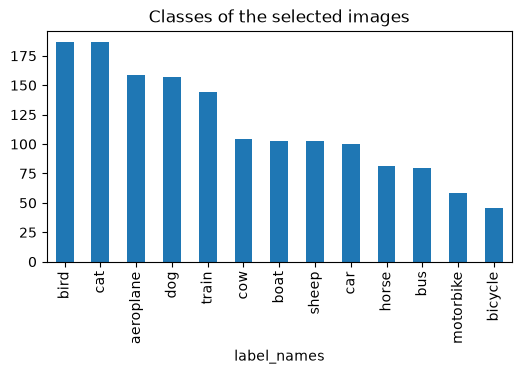

In [2]:
pascal = load_pascal_voc(download=DOWNLOAD)
labels = label_table(pascal)
candidates = single_class_images(labels)
print(f"{len(candidates)} of {len(pascal)} images")
candidates["label_names"].explode().value_counts().plot(kind="bar", figsize=(6, 3), title="Classes of the selected images");

## Saliency methods and metrics

EP = LRP with the Epsilon-Plus rule, GB = Epsilon-Gamma-Box; with a layer name the relevance is taken at that layer instead of the input.

In [3]:
def lrp(composite, layer=None):
    return LRP(resnet, composite(canonizers=[SequentialMergeBatchNorm()]), layer)

epsilon_plus = EpsilonPlus
gamma_box = lambda canonizers: EpsilonGammaBox(low=-3, high=3, canonizers=canonizers)

xai_methods = {
    "GradCAM": GradCAM(resnet, resnet.layer4),
    "EP": lrp(epsilon_plus),
    **{f"EP {layer}": lrp(epsilon_plus, f"layer{layer}") for layer in ("1.0.conv2", "2.0.conv2", "3.0.conv2")},
    "GB": lrp(gamma_box),
    **{f"GB {layer}": lrp(gamma_box, f"layer{layer}") for layer in ("1.0.conv2", "2.0.conv2", "3.0.conv2")},
}

metrics = {
    "iou": IoU(), "precision": Precision(), "recall": Recall(), "f1": F1Score(), "dice": DiceCoefficient(),
    "biou": BoundaryIoU(dilation_radius=3), "asd": AverageSurfaceDistance(),
    "assd": AverageSymmetricSurfaceDistance(dilation_radius=3), "hd": HausdorffDistance(),
    "nsd": NormalizedSurfaceDistance(),
}

## Run on a sample

Per image and method: the selection (gray), the saliency map (red/yellow) and the ground truth outline (green).

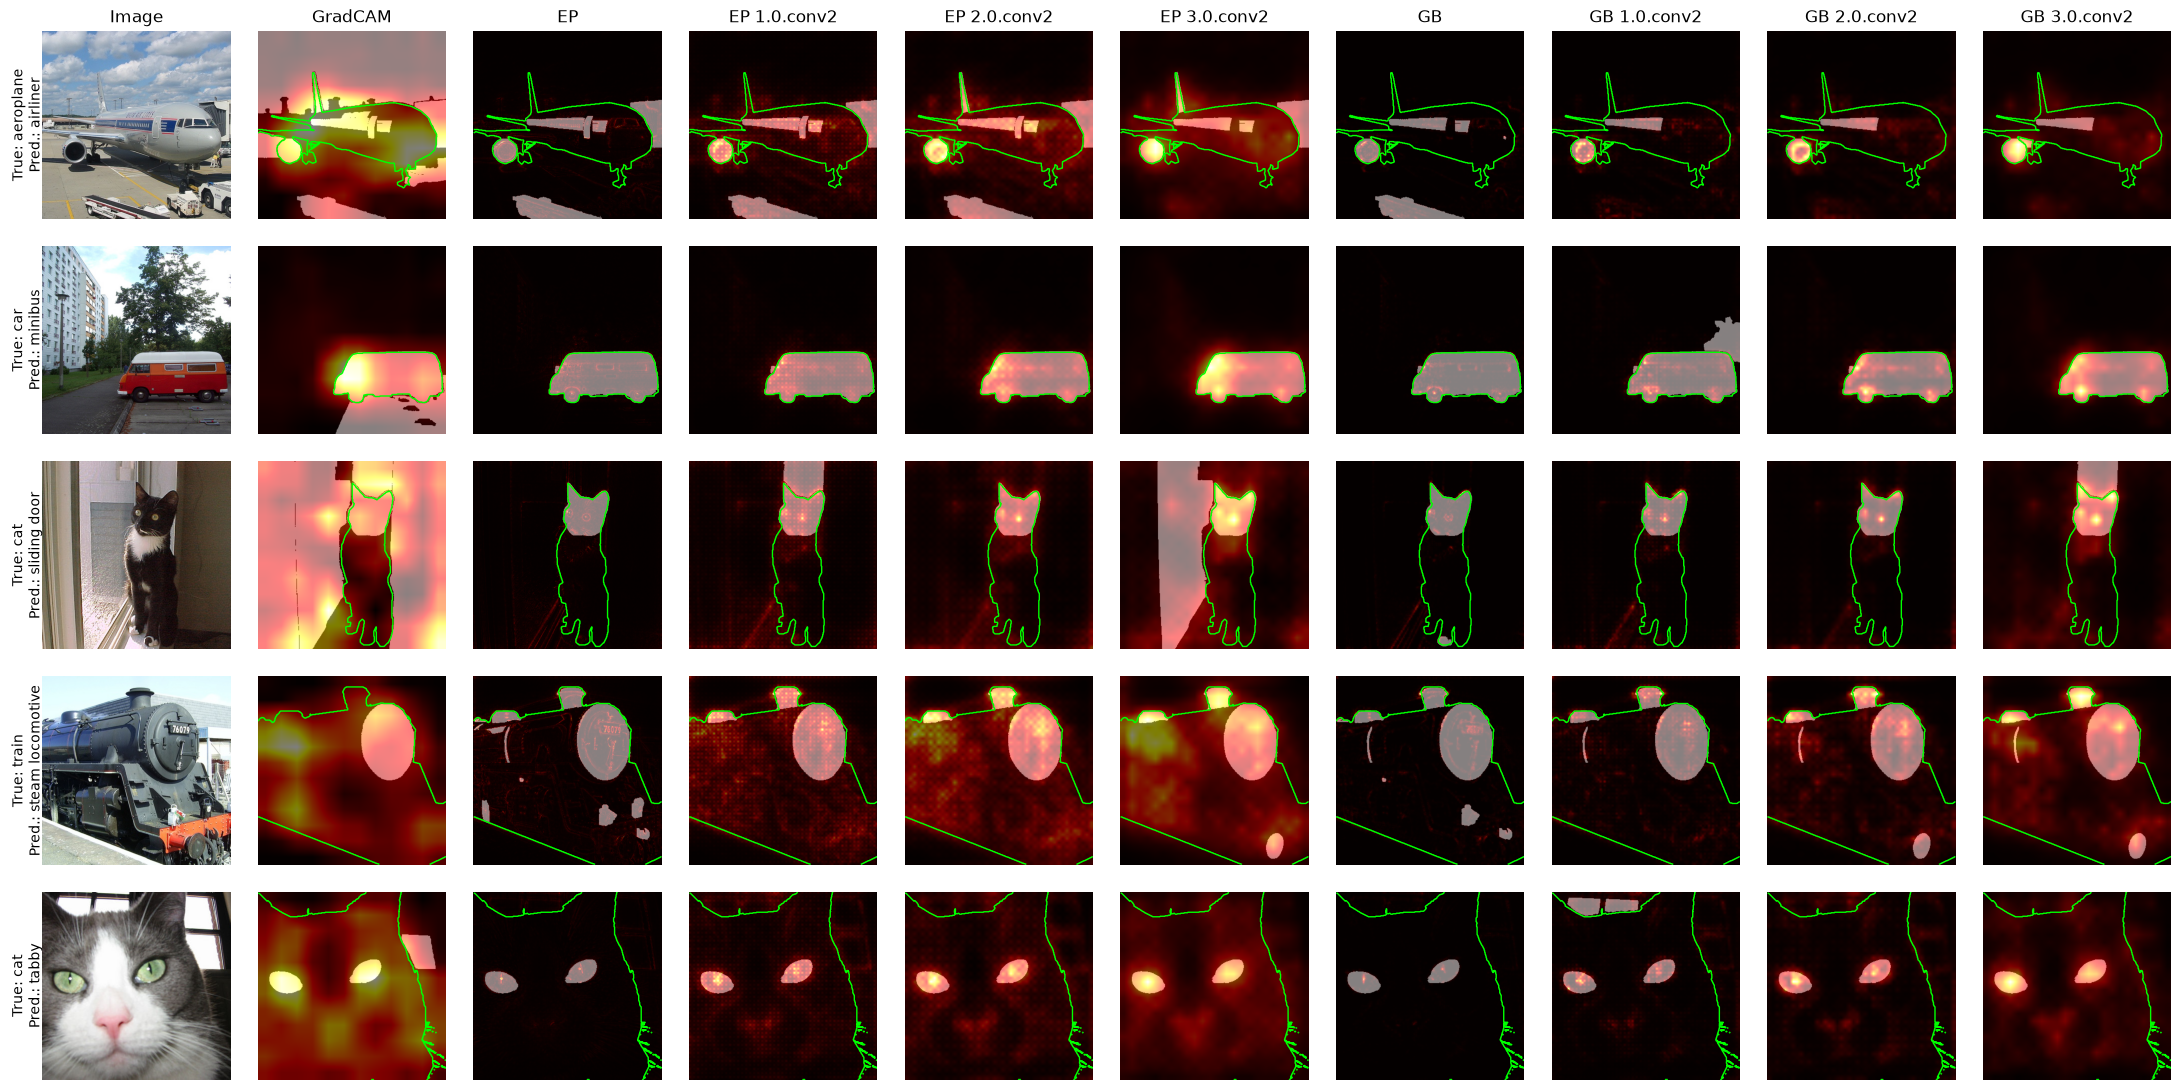

In [4]:
evaluator = Evaluator(resnet, sam, xai_methods, metrics)
sample = random.sample(list(candidates["dataset_idx"]), N_SAMPLES)

outputs = [evaluator(*pascal[idx], idx) for idx in sample]
plotting.evaluation_grid(outputs);

In [5]:
results = evaluator.results
results.groupby("xai_method")[["iou", "dice", "precision", "recall", "biou"]].mean().sort_values("iou", ascending=False)

,iou,dice,precision,recall,biou
xai_method,,,,,
EP,0.318061,0.407772,0.858237,0.333054,0.164938
GB,0.316315,0.404793,0.875968,0.328445,0.169505
EP 2.0.conv2,0.314937,0.402008,0.862621,0.330571,0.189166
GB 2.0.conv2,0.312888,0.400395,0.975524,0.320076,0.167709
GB 3.0.conv2,0.306207,0.390080,0.885139,0.321306,0.170884
EP 1.0.conv2,0.302606,0.385876,0.778591,0.326260,0.172074
EP 3.0.conv2,0.291298,0.367932,0.746537,0.329382,0.188405
GB 1.0.conv2,0.276681,0.376885,0.853962,0.317431,0.167284
GradCAM,0.165586,0.245903,0.449628,0.329637,0.155199


In [6]:
print("saved:", save_results(results, "pascal_voc_sample"))

saved: /home/jovyan/Documents/personal/automatic-image-segmentation/results/pascal_voc_sample_2026-11-15_14-07-49.csv


## Whole dataset (hours)

About 1 000 images × 9 methods; each SAM pass takes a few seconds on a GPU.

In [7]:
# evaluator = Evaluator(resnet, sam, xai_methods, metrics)
# results = evaluator.run(pascal, candidates["dataset_idx"])
# save_results(results, "pascal_voc")